# Understanding Magazine Subscription Behavior
#### **Student:** Rabiat Blessing Ibrahim  
#### **Instructor:** Behzad Abdi  
#### **Course:** ALY6020 - Predictive Analytics
---

## Setup: Data Path
Set `file_path` to wherever your copy of `marketing_campaign.xlsx` lives. In Google Colab you can mount Google Drive first with `from google.colab import drive; drive.mount('/content/drive')`.

In [ ]:
file_path = 'marketing_campaign.xlsx'

## Import Libraries

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score,
    roc_auc_score, roc_curve
)
import warnings
warnings.filterwarnings('ignore')
print('Libraries imported successfully.')

Libraries imported successfully.


---
## Part 1: Data Loading and Cleaning

### Load Dataset

In [21]:
df = pd.read_excel(file_path)

print('Shape:', df.shape)
print('\nColumn Names:')
print(df.columns.tolist())
print('\nData Types:\n', df.dtypes)
print('\nMissing Values:\n', df.isnull().sum()[df.isnull().sum() > 0])

Shape: (2240, 29)

Column Names:
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']

Data Types:
 ID                       int64
Year_Birth               int64
Education               object
Marital_Status          object
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer             object
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPu

### Descriptive Statistics

In [22]:
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


### Data Cleaning Steps
1. Drop constant columns (Z_CostContact, Z_Revenue)
2. Cap Income outlier at 99th percentile
3. Impute 24 missing Income values with median
4. Remove 3 records with Age > 90 (data entry errors)
5. Consolidate non-standard Marital_Status entries

In [23]:
# Step 1: Drop constant columns
df = df.drop(columns=['Z_CostContact', 'Z_Revenue'])
print('Dropped Z_CostContact and Z_Revenue (constant, no predictive value).')

# Step 2: Cap Income outlier at 99th percentile
income_q99 = df['Income'].quantile(0.99)
print(f'Income 99th percentile: ${income_q99:,.0f}')
df['Income'] = df['Income'].clip(upper=income_q99)

# Step 3: Impute missing Income with median
print(f'Missing Income values before imputation: {df["Income"].isnull().sum()}')
df['Income'] = df['Income'].fillna(df['Income'].median())
print(f'Missing Income values after imputation: {df["Income"].isnull().sum()}')

# Step 4: Remove extreme ages (> 90)
df['Age'] = 2024 - df['Year_Birth']
print(f'\nRows with Age > 90: {(df["Age"] > 90).sum()}')
df = df[df['Age'] <= 90].copy()
print(f'Shape after removing extreme ages: {df.shape}')

# Step 5: Clean Marital_Status
df['Marital_Status'] = df['Marital_Status'].replace(
    {'Alone': 'Single', 'Absurd': 'Single', 'YOLO': 'Single'}
)
print('\nMarital Status distribution after cleaning:')
print(df['Marital_Status'].value_counts())

Dropped Z_CostContact and Z_Revenue (constant, no predictive value).
Income 99th percentile: $94,459
Missing Income values before imputation: 24
Missing Income values after imputation: 0

Rows with Age > 90: 3
Shape after removing extreme ages: (2237, 28)

Marital Status distribution after cleaning:
Marital_Status
Married     864
Together    579
Single      486
Divorced    231
Widow        77
Name: count, dtype: int64


### Feature Engineering

In [24]:
# Aggregate spending across all product categories
spend_cols = ['MntWines', 'MntFruits', 'MntMeatProducts',
              'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
df['TotalSpend'] = df[spend_cols].sum(axis=1)

# Aggregate purchases across all channels
purch_cols = ['NumDealsPurchases', 'NumWebPurchases',
              'NumCatalogPurchases', 'NumStorePurchases']
df['TotalPurchases'] = df[purch_cols].sum(axis=1)

# Total number of past campaigns accepted
df['TotalCampaignsAccepted'] = df[[
    'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3',
    'AcceptedCmp4', 'AcceptedCmp5'
]].sum(axis=1)

# Total number of children at home
df['Children'] = df['Kidhome'] + df['Teenhome']

# Ordinal encoding for Education level
edu_map = {'Basic': 0, '2n Cycle': 1, 'Graduation': 2, 'Master': 3, 'PhD': 4}
df['EducationOrd'] = df['Education'].map(edu_map)

# Binary: Is the customer in a partnered relationship?
df['IsCouple'] = df['Marital_Status'].isin(['Married', 'Together']).astype(int)

# Customer tenure in days (enrollment date to Jan 1, 2015)
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'])
df['CustomerTenure'] = (pd.Timestamp('2015-01-01') - df['Dt_Customer']).dt.days

print('Engineered features added: TotalSpend, TotalPurchases, TotalCampaignsAccepted,')
print('Children, EducationOrd, IsCouple, CustomerTenure')
print(f'\nFinal dataset shape: {df.shape}')

Engineered features added: TotalSpend, TotalPurchases, TotalCampaignsAccepted,
Children, EducationOrd, IsCouple, CustomerTenure

Final dataset shape: (2237, 35)


### Class Distribution (Target Variable)

In [25]:
print('Response (Subscription) distribution:')
print(df['Response'].value_counts())
print(f'\nSubscription rate: {df["Response"].mean()*100:.1f}%')
print('Note: The dataset is imbalanced. class_weight="balanced" will be used in models.')

Response (Subscription) distribution:
Response
0    1903
1     334
Name: count, dtype: int64

Subscription rate: 14.9%
Note: The dataset is imbalanced. class_weight="balanced" will be used in models.


### Exploratory Visualizations

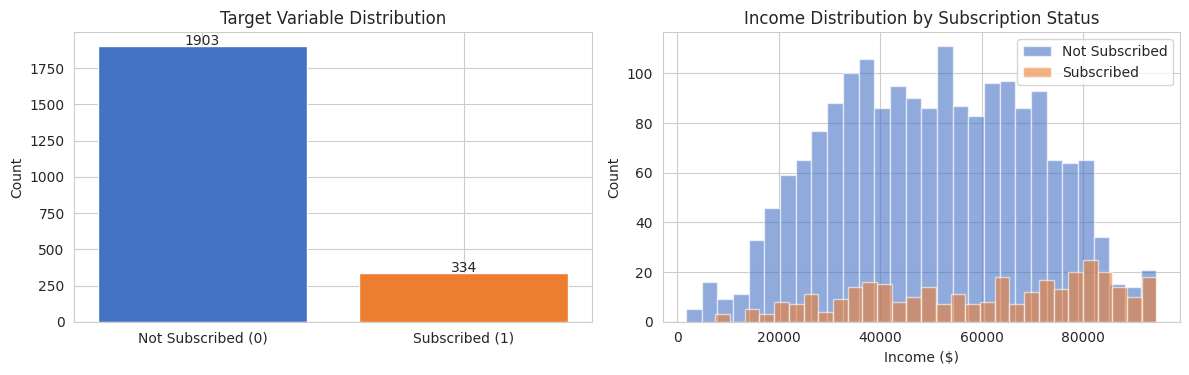

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Class distribution bar chart
counts = df['Response'].value_counts()
axes[0].bar(['Not Subscribed (0)', 'Subscribed (1)'], counts.values,
            color=['#4472C4', '#ED7D31'])
for i, count in enumerate(counts.values):
    axes[0].text(i, count + 10, str(count), ha='center')
axes[0].set_title('Target Variable Distribution')
axes[0].set_ylabel('Count')

# Income distribution by Response
for response, color, label in [(0,'#4472C4','Not Subscribed'), (1,'#ED7D31','Subscribed')]:
    subset = df[df['Response']==response]['Income']
    axes[1].hist(subset, bins=30, alpha=0.6, color=color, label=label)
axes[1].set_title('Income Distribution by Subscription Status')
axes[1].set_xlabel('Income ($)')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.suptitle('')
plt.tight_layout()
plt.show()

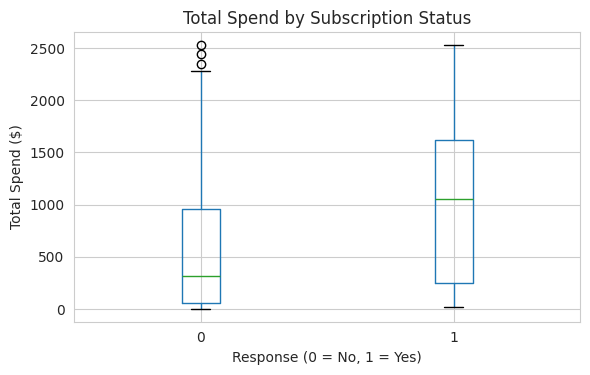

In [27]:
# Total Spend by Response
fig, ax = plt.subplots(figsize=(6, 4))
df.boxplot(column='TotalSpend', by='Response', ax=ax)
ax.set_title('Total Spend by Subscription Status')
ax.set_xlabel('Response (0 = No, 1 = Yes)')
ax.set_ylabel('Total Spend ($)')
plt.suptitle('')
plt.tight_layout()
plt.show()

---
## Prepare Data for Modeling

In [28]:
features = [
    'Age', 'Income', 'EducationOrd', 'IsCouple', 'Children',
    'Recency', 'TotalSpend', 'TotalPurchases', 'TotalCampaignsAccepted',
    'NumWebVisitsMonth', 'CustomerTenure', 'Complain'
]

X = df[features].copy()
y = df['Response']

# 80/20 train-test split, stratified to preserve class balance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize: fit on train, transform both
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print(f'Training set: {X_train.shape[0]} rows')
print(f'Test set:     {X_test.shape[0]} rows')
print(f'Features:     {len(features)}')

Training set: 1789 rows
Test set:     448 rows
Features:     12


---
## Part 2: Logistic Regression Model

In [29]:
lr = LogisticRegression(class_weight='balanced', max_iter=500, random_state=42)
lr.fit(X_train_sc, y_train)

y_pred_lr = lr.predict(X_test_sc)
y_prob_lr = lr.predict_proba(X_test_sc)[:, 1]

print('===== Logistic Regression: Classification Report =====')
print(classification_report(y_test, y_pred_lr))
print(f'AUC: {roc_auc_score(y_test, y_prob_lr):.4f}')

===== Logistic Regression: Classification Report =====
              precision    recall  f1-score   support

           0       0.95      0.77      0.85       381
           1       0.37      0.75      0.49        67

    accuracy                           0.77       448
   macro avg       0.66      0.76      0.67       448
weighted avg       0.86      0.77      0.80       448

AUC: 0.8652


### Logistic Regression: Coefficients

Coefficients sorted by absolute magnitude:
               Feature  Coefficient
TotalCampaignsAccepted     1.043947
               Recency    -0.967884
        CustomerTenure     0.935630
              IsCouple    -0.511220
            TotalSpend     0.451852
          EducationOrd     0.418599
        TotalPurchases    -0.269118
     NumWebVisitsMonth     0.233463
              Children    -0.210235
                Income    -0.076761
                   Age    -0.027797
              Complain    -0.002350


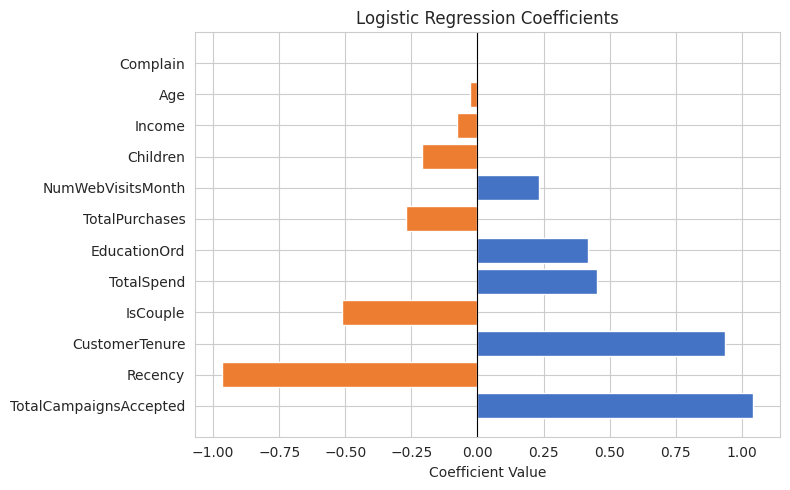

In [30]:
coef_df = pd.DataFrame({'Feature': features, 'Coefficient': lr.coef_[0]})
coef_df = coef_df.reindex(coef_df['Coefficient'].abs().sort_values(ascending=False).index)
print('Coefficients sorted by absolute magnitude:')
print(coef_df.to_string(index=False))

# Plot
plt.figure(figsize=(8, 5))
colors = ['#ED7D31' if c < 0 else '#4472C4' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Logistic Regression Coefficients')
plt.xlabel('Coefficient Value')
plt.tight_layout()
plt.show()

### Logistic Regression: Confusion Matrix

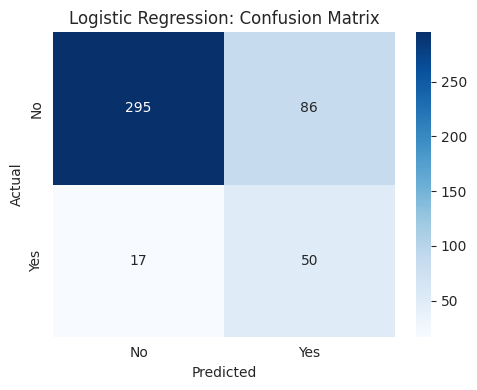

In [31]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.title('Logistic Regression: Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

---
## Part 3: SVM Model

In [32]:
svm = SVC(kernel='rbf', class_weight='balanced',
          probability=True, random_state=42, C=1.0, gamma='scale')
svm.fit(X_train_sc, y_train)

y_pred_svm = svm.predict(X_test_sc)
y_prob_svm = svm.predict_proba(X_test_sc)[:, 1]

print('===== SVM: Classification Report =====')
print(classification_report(y_test, y_pred_svm))
print(f'AUC: {roc_auc_score(y_test, y_prob_svm):.4f}')

===== SVM: Classification Report =====
              precision    recall  f1-score   support

           0       0.94      0.81      0.87       381
           1       0.40      0.73      0.52        67

    accuracy                           0.79       448
   macro avg       0.67      0.77      0.69       448
weighted avg       0.86      0.79      0.82       448

AUC: 0.8670


### SVM: Confusion Matrix

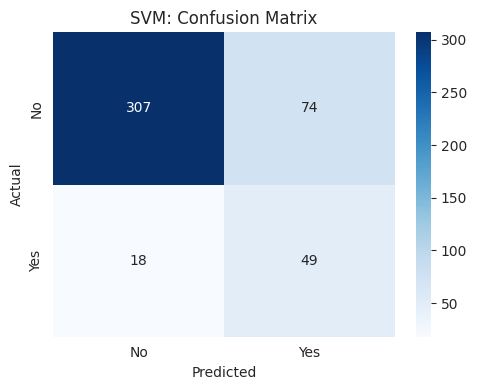

In [33]:
cm_svm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.title('SVM: Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

---
## Part 4: Model Comparison

In [34]:
lr_acc  = accuracy_score(y_test, y_pred_lr)
lr_prec = precision_score(y_test, y_pred_lr)
lr_rec  = recall_score(y_test, y_pred_lr)
lr_auc  = roc_auc_score(y_test, y_prob_lr)

svm_acc  = accuracy_score(y_test, y_pred_svm)
svm_prec = precision_score(y_test, y_pred_svm)
svm_rec  = recall_score(y_test, y_pred_svm)
svm_auc  = roc_auc_score(y_test, y_prob_svm)

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'AUC'],
    'Logistic Regression': [f'{lr_acc*100:.2f}%', f'{lr_prec*100:.2f}%',
                            f'{lr_rec*100:.2f}%', f'{lr_auc*100:.2f}%'],
    'SVM': [f'{svm_acc*100:.2f}%', f'{svm_prec*100:.2f}%',
            f'{svm_rec*100:.2f}%', f'{svm_auc*100:.2f}%']
})
print(comparison.to_string(index=False))

   Metric Logistic Regression    SVM
 Accuracy              77.01% 79.46%
Precision              36.76% 39.84%
   Recall              74.63% 73.13%
      AUC              86.52% 86.70%


### ROC Curves

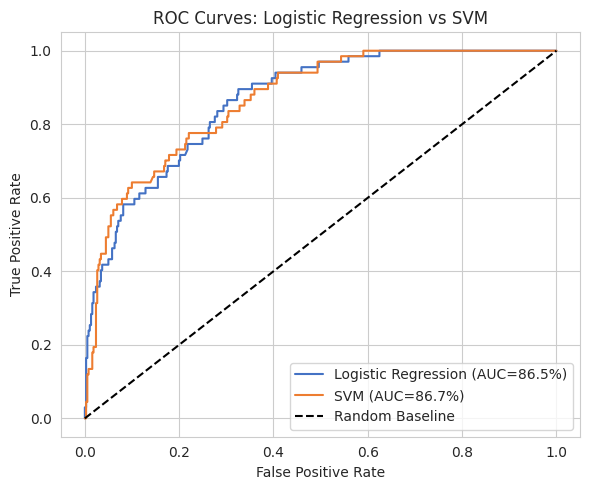

In [35]:
plt.figure(figsize=(6, 5))
fpr_lr,  tpr_lr,  _ = roc_curve(y_test, y_prob_lr)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
plt.plot(fpr_lr,  tpr_lr,  color='#4472C4',
         label=f'Logistic Regression (AUC={lr_auc*100:.1f}%)')
plt.plot(fpr_svm, tpr_svm, color='#ED7D31',
         label=f'SVM (AUC={svm_auc*100:.1f}%)')
plt.plot([0, 1], [0, 1], 'k--', label='Random Baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves: Logistic Regression vs SVM')
plt.legend()
plt.tight_layout()
plt.show()